# Exercise 1 · Batch Pipeline — Customer RFM Segmentation

## The problem

You have 6 months of e-commerce transactions. Your goal is to build a batch pipeline that segments customers using the **RFM model**:

| Metric | Question | How to compute |
|---|---|---|
| **R**ecency | How recently did they buy? | Days since last purchase |
| **F**requency | How often do they buy? | Number of orders |
| **M**onetary | How much do they spend? | Total spend |

Each metric is scored 1–5 (5 = best). Scores are combined to classify customers into segments like *Champions*, *Loyal*, *At Risk*, and *Lost*.

## Pipeline
```
Generate data  →  Compute RFM  →  Score 1-5  →  Segment
      ↓                                              ↓
  PostgreSQL                               Parquet + DuckDB
```

## Skills practiced
- Multi-source reads (JDBC + in-memory)
- `groupBy` + `agg` for metric computation
- `ntile()` window function for percentile scoring
- JDBC write to PostgreSQL
- DuckDB for final analytics and visualisation

---
## Step 0 · Setup

In [1]:
import os
from datetime import date, timedelta
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window
from pyspark.sql.types import *
import random
from faker import Faker

SPARK_MASTER = os.getenv('SPARK_MASTER', 'spark://spark-master:7077')
PG_URL   = f"jdbc:postgresql://{os.getenv('POSTGRES_HOST','postgres')}:5432/{os.getenv('POSTGRES_DB','sandbox')}"
PG_PROPS = {'user': os.getenv('POSTGRES_USER','spark'),
            'password': os.getenv('POSTGRES_PASSWORD','spark123'),
            'driver': 'org.postgresql.Driver'}

spark = (
    SparkSession.builder
    .appName('rfm-pipeline')
    .master(SPARK_MASTER)
    .getOrCreate()
)
spark.sparkContext.setLogLevel('WARN')
print(f'Spark {spark.version}  master: {spark.sparkContext.master}')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/07/01 20:22:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/07/01 20:22:59 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 4.0.3  master: spark://spark-master:7077


---
## Step 1 · Generate synthetic transactions

We generate 500 customers with 6 months of purchases.
Some are frequent buyers, some churned long ago — this makes the segmentation interesting.

In [21]:
fake = Faker()
Faker.seed(0)
random.seed(0)

TODAY      =  date.today()
START_DATE = TODAY - timedelta(days=180)
N_CUSTOMERS = 500
CATEGORIES  = ['electronics', 'clothing', 'food', 'travel', 'health']

# Each customer has a "persona" that shapes their buying pattern
def customer_persona(cid):
    if cid % 5 == 0:  return 'champion'    # frequent, recent, high spend
    if cid % 5 == 1:  return 'loyal'       # frequent, recent, medium spend
    if cid % 5 == 2:  return 'at_risk'     # used to buy, went quiet
    if cid % 5 == 3:  return 'new'         # one recent purchase
    return 'lost'                           # bought once, long ago

rows = []
for cid in range(1, N_CUSTOMERS + 1):
    persona = customer_persona(cid)
    if persona == 'champion':
        n_orders, recency_cap, spend_range = 20, 14,  (100, 800)
    elif persona == 'loyal':
        n_orders, recency_cap, spend_range = 10, 30,  (40,  300)
    elif persona == 'at_risk':
        n_orders, recency_cap, spend_range =  5, 180, (20,  200)
    elif persona == 'new':
        n_orders, recency_cap, spend_range =  1, 7,   (30,  150)
    else:  # lost
        n_orders, recency_cap, spend_range =  1, 180, (10,  100)

    last_purchase_days_ago = random.randint(1, recency_cap)
    for _ in range(n_orders):
        order_date = TODAY - timedelta(
            days=random.randint(last_purchase_days_ago, 180)
        )
        if order_date < START_DATE:
            continue
        rows.append((
            cid,
            fake.name(),
            fake.country_code(),
            round(random.uniform(*spend_range), 2),
            random.choice(CATEGORIES),
            order_date.isoformat(),
        ))

schema = StructType([
    StructField('customer_id',  IntegerType()),
    StructField('customer_name',StringType()),
    StructField('country',      StringType()),
    StructField('amount',       DoubleType()),
    StructField('category',     StringType()),
    StructField('order_date',   StringType()),
])

raw = spark.createDataFrame(rows, schema).withColumn('order_date', F.to_date('order_date'))
print(f'Total orders: {raw.count():,}   Distinct customers: {raw.select("customer_id").distinct().count()}')
raw.show(5)

Total orders: 3,700   Distinct customers: 500
+-----------+--------------+-------+------+--------+----------+
|customer_id| customer_name|country|amount|category|order_date|
+-----------+--------------+-------+------+--------+----------+
|          1|  Norma Fisher|     IL|237.07|  travel|2026-02-25|
|          1|  Katelyn Hull|     KI|107.32|  health|2026-05-24|
|          1|  Heather Snow|     GM|145.28|    food|2026-01-30|
|          1|  Diane Campos|     VN|133.09|clothing|2026-02-01|
|          1|Victoria Patel|     MA| 76.21|clothing|2026-01-25|
+-----------+--------------+-------+------+--------+----------+
only showing top 5 rows


---
## Step 2 · Compute RFM metrics

Per customer we need:
- **R** = days between `TODAY` and the most recent `order_date`
- **F** = count of distinct orders
- **M** = sum of `amount`

In [22]:
snapshot = F.to_date(F.lit(TODAY.isoformat()))

rfm = (
    raw.groupBy('customer_id', 'customer_name', 'country')
    .agg(
        F.datediff(snapshot, F.max('order_date')).alias('recency'),    # lower = better
        F.count('*').alias('frequency'),                                # higher = better
        F.round(F.sum('amount'), 2).alias('monetary'),                  # higher = better
    )
)

rfm.orderBy('recency').show(100)

+-----------+-------------------+-------+-------+---------+--------+
|customer_id|      customer_name|country|recency|frequency|monetary|
+-----------+-------------------+-------+-------+---------+--------+
|        101|   Jennifer Calhoun|     TZ|      1|        1|  254.62|
|        425|       Thomas Smith|     GQ|      2|        1|  773.32|
|        280| Christopher Hebert|     BW|      2|        1|  477.54|
|        492|    Jesse Jones Jr.|     CI|      2|        1|   82.31|
|         15|   Amanda Hernandez|     IE|      3|        1|  196.92|
|        250|   Patricia Stewart|     BB|      3|        1|  626.36|
|        365|       Krista Allen|     FM|      4|        1|  613.56|
|         51|      Robin Vega MD|     AF|      5|        1|  244.97|
|        380|      Jacob Baldwin|     US|      5|        1|  375.12|
|        370|     Kimberly Allen|     KN|      5|        1|  751.05|
|        215|      Jeffrey Pitts|     UG|      6|        1|   313.9|
|        101|     Darrell Rivera| 

---
## Step 3 · Score each metric 1–5 using `ntile()`

`ntile(5)` splits the population into 5 equal buckets ordered by the metric.
**Important:** recency is reversed — a *lower* number of days is *better*, so we order descending.

In [23]:
# Window specs — ntile needs an ORDER BY
w_r = Window.orderBy(F.col('recency').asc())     # fewer days → higher score (5)
w_f = Window.orderBy(F.col('frequency').asc())
w_m = Window.orderBy(F.col('monetary').asc())

scored = (
    rfm
    .withColumn('r_score', F.ntile(5).over(w_r))
    .withColumn('f_score', F.ntile(5).over(w_f))
    .withColumn('m_score', F.ntile(5).over(w_m))
    # Invert recency: ntile(1) = smallest recency (best) → should be score 5
    .withColumn('r_score', F.lit(6) - F.col('r_score'))
    .withColumn('rfm_score', F.col('r_score') + F.col('f_score') + F.col('m_score'))
)

scored.select('customer_id', 'recency', 'frequency', 'monetary',
              'r_score', 'f_score', 'm_score', 'rfm_score') \
      .orderBy(F.col('rfm_score').desc()) \
      .show(10)

+-----------+-------+---------+--------+-------+-------+-------+---------+
|customer_id|recency|frequency|monetary|r_score|f_score|m_score|rfm_score|
+-----------+-------+---------+--------+-------+-------+-------+---------+
|        210|     18|        1|  545.71|      5|      1|      5|       11|
|        150|     15|        1|  550.06|      5|      1|      5|       11|
|        305|    120|        1|  546.09|      3|      3|      5|       11|
|        160|     64|        1|   546.1|      4|      2|      5|       11|
|        240|     46|        1|  546.13|      5|      1|      5|       11|
|        455|     25|        1|  547.05|      5|      1|      5|       11|
|        220|     55|        1|  547.13|      4|      2|      5|       11|
|        135|    115|        1|  547.86|      3|      3|      5|       11|
|        460|     34|        1|  548.93|      5|      1|      5|       11|
|        390|    149|        1|   549.3|      2|      4|      5|       11|
+-----------+-------+----

26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

---
## Step 4 · Assign segments

Map the combined RFM score (3–15) to human-readable segments.

| Score range | Segment |
|---|---|
| 13–15 | Champions |
| 10–12 | Loyal |
| 7–9 | Needs Attention |
| 4–6 | At Risk |
| 3 | Lost |

In [24]:
segmented = scored.withColumn(
    'segment',
    F.when(F.col('rfm_score') >= 13, 'Champions')
     .when(F.col('rfm_score') >= 10, 'Loyal')
     .when(F.col('rfm_score') >= 7,  'Needs Attention')
     .when(F.col('rfm_score') >= 4,  'At Risk')
     .otherwise('Lost')
)

# Distribution check
segmented.groupBy('segment') \
         .agg(F.count('*').alias('customers'),
              F.round(F.avg('monetary'), 2).alias('avg_spend')) \
         .orderBy('customers', ascending=False) \
         .show()

+---------------+---------+---------+
|        segment|customers|avg_spend|
+---------------+---------+---------+
|Needs Attention|     2220|   154.45|
|          Loyal|     1480|   545.24|
+---------------+---------+---------+



26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

---
## Step 5 · Write results

In [25]:
# Write to PostgreSQL
(
    segmented
    .select('customer_id', 'customer_name', 'country',
            'recency', 'frequency', 'monetary',
            'r_score', 'f_score', 'm_score', 'rfm_score', 'segment')
    .write.jdbc(
        PG_URL, 'customer_rfm', mode='overwrite',
        properties={**PG_PROPS,
                    'truncate': 'false',          # full drop+create — schema changes each run
                    'createTableColumnTypes':
                        'customer_id INT, customer_name VARCHAR(120), country CHAR(2), '
                        'recency INT, frequency INT, monetary FLOAT, '
                        'r_score INT, f_score INT, m_score INT, rfm_score INT, '
                        'segment VARCHAR(20)'}
    )
)
print('PostgreSQL ✓')

PostgreSQL ✓


26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

In [26]:
# Write to Parquet for DuckDB analysis
segmented.write.mode('overwrite').parquet('/home/jupyter/data/output/rfm')
print('Parquet ✓')

26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:41:17 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

Parquet ✓


---
## Step 6 · Analyze with DuckDB

In [27]:
import duckdb, matplotlib.pyplot as plt

con = duckdb.connect()
con.execute("CREATE VIEW rfm AS SELECT * FROM read_parquet('/home/jupyter/data/output/rfm/**/*.parquet')")

# Segment summary
summary = con.execute("""
    SELECT segment,
           COUNT(*)                         AS customers,
           ROUND(AVG(recency), 1)           AS avg_days_since_purchase,
           ROUND(AVG(frequency), 1)         AS avg_orders,
           ROUND(AVG(monetary), 2)          AS avg_spend,
           ROUND(SUM(monetary), 2)          AS total_revenue
    FROM rfm
    GROUP BY ALL
    ORDER BY avg_spend DESC
""").df()

summary

,segment,customers,avg_days_since_purchase,avg_orders,avg_spend,total_revenue
0,Loyal,1480,95.5,1.0,545.24,806953.45
1,Needs Attention,2220,106.9,1.0,154.45,342886.95


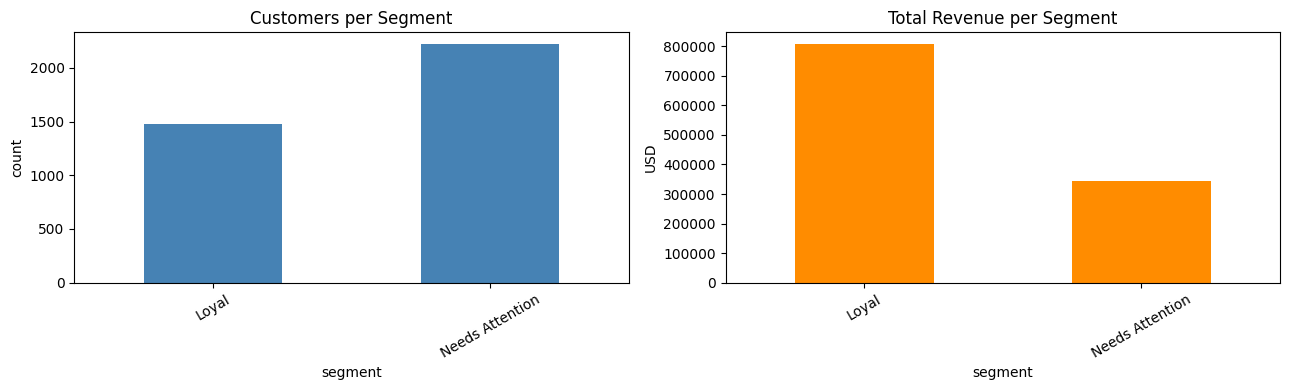

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

summary.set_index('segment')['customers'].plot(
    kind='bar', ax=axes[0], color='steelblue', title='Customers per Segment')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=30)

summary.set_index('segment')['total_revenue'].plot(
    kind='bar', ax=axes[1], color='darkorange', title='Total Revenue per Segment')
axes[1].set_ylabel('USD')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

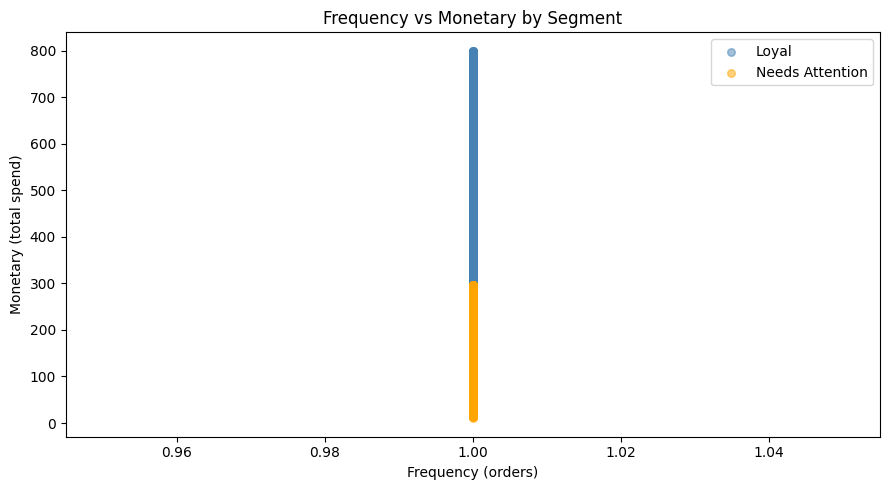

In [29]:
# Scatter: Frequency vs Monetary coloured by Segment — spot outliers
detail = con.execute("SELECT frequency, monetary, segment FROM rfm").df()

colours = {'Champions':'gold', 'Loyal':'steelblue', 'Needs Attention':'orange',
           'At Risk':'tomato', 'Lost':'grey'}

fig, ax = plt.subplots(figsize=(9, 5))
for seg, grp in detail.groupby('segment'):
    ax.scatter(grp['frequency'], grp['monetary'], label=seg,
               color=colours.get(seg,'black'), alpha=0.5, s=30)

ax.set_xlabel('Frequency (orders)')
ax.set_ylabel('Monetary (total spend)')
ax.set_title('Frequency vs Monetary by Segment')
ax.legend()
plt.tight_layout()
plt.show()

---
## Challenge — try it yourself

1. **Add a category dimension** — which segment buys most electronics vs food? Pivot the result.
2. **Country filter** — re-run the RFM only for `country = 'US'`. Do the segment proportions change?
3. **Stricter Champions** — change the Champions threshold to require `r_score = 5 AND f_score >= 4`. How many remain?
4. **Delta Lake** — replace the Parquet write with a Delta Lake write (`format('delta')`). Then do an UPDATE to set `segment = 'VIP'` for customers with `rfm_score = 15`.

In [35]:
## 1. Add a category dimension to the RFM analysis
rfm_category = (
    raw.groupBy('customer_id', 'customer_name', 'country', 'category')
    .agg(
        F.datediff(snapshot, F.max('order_date')).alias('recency'),    # lower = better
        F.count('*').alias('frequency'),                                # higher = better
        F.round(F.sum('amount'), 2).alias('monetary'),                  # higher = better
    )
)

scored_category = (
    rfm_category
    .withColumn('r_score', F.ntile(5).over(w_r))
    .withColumn('f_score', F.ntile(5).over(w_f))
    .withColumn('m_score', F.ntile(5).over(w_m))
    # Invert recency: ntile(1) = smallest recency (best) → should be score 5
    .withColumn('r_score', F.lit(6) - F.col('r_score'))
    .withColumn('rfm_score', F.col('r_score') + F.col('f_score') + F.col('m_score'))
)

segmented_category = scored_category.withColumn(
    'segment',
    F.when((F.col('r_score') > 5 )& (F.col('f_score') >= 4), 'Champions')
        .when(F.col('rfm_score') >= 10, 'Loyal')
        .when(F.col('rfm_score') >= 7,  'Needs Attention')
        .when(F.col('rfm_score') >= 4,  'At Risk')
        .otherwise('Lost')
)

summary_category = (
    segmented_category
    .groupBy('category', 'segment')
    .agg(F.count('*').alias('customers'),
         F.round(F.avg('monetary'), 2).alias('avg_spend'),
         F.round(F.sum('monetary'), 2).alias('total_revenue'))
    .orderBy('category', 'segment')
)

summary_category_us = (
    segmented_category.filter(F.col('country') == 'US')
    .groupBy('category', 'segment')
    .agg(F.count('*').alias('customers'),
         F.round(F.avg('monetary'), 2).alias('avg_spend'),
         F.round(F.sum('monetary'), 2).alias('total_revenue'))
    .orderBy('category', 'segment')
)

print('All countries')
summary_category.show(20)
print('US only')
summary_category_us.show(20)



All countries


26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:36 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

+-----------+---------------+---------+---------+-------------+
|   category|        segment|customers|avg_spend|total_revenue|
+-----------+---------------+---------+---------+-------------+
|   clothing|          Loyal|      315|    553.5|    174353.85|
|   clothing|Needs Attention|      452|   153.92|     69573.25|
|electronics|          Loyal|      279|   544.51|    151917.49|
|electronics|Needs Attention|      448|   157.48|     70552.04|
|       food|          Loyal|      303|   547.66|    165939.48|
|       food|Needs Attention|      445|   157.23|     69965.23|
|     health|          Loyal|      286|   535.48|    153146.66|
|     health|Needs Attention|      416|    156.9|     65272.22|
|     travel|          Loyal|      297|   544.09|    161595.97|
|     travel|Needs Attention|      459|   147.11|     67524.21|
+-----------+---------------+---------+---------+-------------+

US only


26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:43:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

+-----------+---------------+---------+---------+-------------+
|   category|        segment|customers|avg_spend|total_revenue|
+-----------+---------------+---------+---------+-------------+
|   clothing|          Loyal|        1|   734.52|       734.52|
|electronics|          Loyal|        1|   565.98|       565.98|
|electronics|Needs Attention|        1|   258.98|       258.98|
|       food|          Loyal|        1|   375.12|       375.12|
|       food|Needs Attention|        2|    89.64|       179.27|
|     health|          Loyal|        1|   439.53|       439.53|
|     health|Needs Attention|        1|   215.08|       215.08|
|     travel|          Loyal|        1|   518.11|       518.11|
|     travel|Needs Attention|        4|    198.7|       794.79|
+-----------+---------------+---------+---------+-------------+



In [46]:
# delta_lake
# 4. **Delta Lake** — replace the Parquet write with a Delta Lake write (`format('delta')`). 
# Then do an UPDATE to set `segment = 'VIP'` for customers with `rfm_score = max`.
segmented_category.write.format('delta').mode('overwrite').save('/home/jupyter/data/output/rfm_delta')

26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 20:48:57 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/07/01 2

In [48]:
segmented_cat_delta = spark.read.format('delta').load('/home/jupyter/data/output/rfm_delta')

max = segmented_cat_delta.select(F.max('rfm_score')).collect()[0][0]

segmented_cat_delta.withColumn('segment', F.when(F.col('rfm_score') == max, 'VIP').otherwise(F.col('segment'))) \
    .write.format('delta').mode('overwrite').save('/home/jupyter/data/output/rfm_delta')

In [51]:
new_seg_cat_delta = spark.read.format('delta').load('/home/jupyter/data/output/rfm_delta')
new_seg_cat_delta.groupBy('segment').agg(F.count('*').alias('customers'),
                                         F.round(F.avg('monetary'), 2).alias('avg_spend'),
                                         F.round(F.sum('monetary'), 2).alias('total_revenue')).show()

+---------------+---------+---------+-------------+
|        segment|customers|avg_spend|total_revenue|
+---------------+---------+---------+-------------+
|          Loyal|      740|   415.28|    307308.56|
|Needs Attention|     2220|   154.45|    342886.95|
|            VIP|      740|    675.2|    499644.89|
+---------------+---------+---------+-------------+



In [55]:
prev_ver_seg_cat_delta = spark.read.format('delta').option('versionAsOf', 1).load('/home/jupyter/data/output/rfm_delta')
prev_ver_seg_cat_delta.groupBy('segment').agg(F.count('*').alias('customers'),
                                         F.round(F.avg('monetary'), 2).alias('avg_spend'),
                                         F.round(F.sum('monetary'), 2).alias('total_revenue')).show()

+---------------+---------+---------+-------------+
|        segment|customers|avg_spend|total_revenue|
+---------------+---------+---------+-------------+
|          Loyal|      740|   415.28|    307308.56|
|Needs Attention|     2220|   154.45|    342886.95|
|            VIP|      740|    675.2|    499644.89|
+---------------+---------+---------+-------------+



26/07/01 20:53:13 ERROR StandaloneSchedulerBackend: Application has been killed. Reason: Master removed our application: KILLED
26/07/01 20:53:13 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exiting due to error from cluster scheduler: Master removed our application: KILLED
	at org.apache.spark.errors.SparkCoreErrors$.clusterSchedulerError(SparkCoreErrors.scala:295)
	at org.apache.spark.scheduler.TaskSchedulerImpl.error(TaskSchedulerImpl.scala:955)
	at org.apache.spark.scheduler.cluster.StandaloneSchedulerBackend.dead(StandaloneSchedulerBackend.scala:166)
	at org.apache.spark.deploy.client.StandaloneAppClient$ClientEndpoint.markDead(StandaloneAppClient.scala:273)
	at org.apache.spark.deploy.client.StandaloneAppClient$ClientEndpoint$$anonfun$receive$1.applyOrElse(StandaloneAppClient.scala:174)
	at org.apache.spark.rpc.netty.Inbox.$anonfun$process$1(Inbox.scala:116)
	at org.apache.spark.rpc.netty.Inbox.safelyCall(Inbox.scala:216)
	at org.apache.spark.rpc.netty.Inbox.proce